In [1]:
import os
from pathlib import Path


# Make sure we are in the root directory
def set_project_root(marker="pyproject.toml"):
    """Change the working directory to the repository root."""
    path = Path.cwd()
    for parent in [path, *path.parents]:
        if (parent / marker).exists():
            os.chdir(parent)
            return parent
    raise FileNotFoundError(f"Could not find {marker} in any parent directory")

set_project_root()

import pandas as pd

In [2]:
import numpy as np
from implementations.tabular_data.haoli_implementation.utils import extract_data_from_pkl
from implementations.tabular_data.haoli_implementation.utils import read_json_file
input_path = Path("implementations/tabular_data/single_table/results/models/None_trans_ckpt.pkl")
file=extract_data_from_pkl(input_path);
file

/home/coder/synthetic-data-bootcamp/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


ClavaDDPMModelArtifacts(diffusion=GaussianMultinomialDiffusion(
  (_denoise_fn): MLPDiffusion(
    (mlp): MLP(
      (blocks): ModuleList(
        (0): Block(
          (linear): Linear(in_features=128, out_features=512, bias=True)
          (activation): ReLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (1): Block(
          (linear): Linear(in_features=512, out_features=1024, bias=True)
          (activation): ReLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (2-4): 3 x Block(
          (linear): Linear(in_features=1024, out_features=1024, bias=True)
          (activation): ReLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (5): Block(
          (linear): Linear(in_features=1024, out_features=512, bias=True)
          (activation): ReLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
      )
      (head): Linear(in_features=512, out_features=36, bias=True)
    )
    (proj): Linear(in_features=

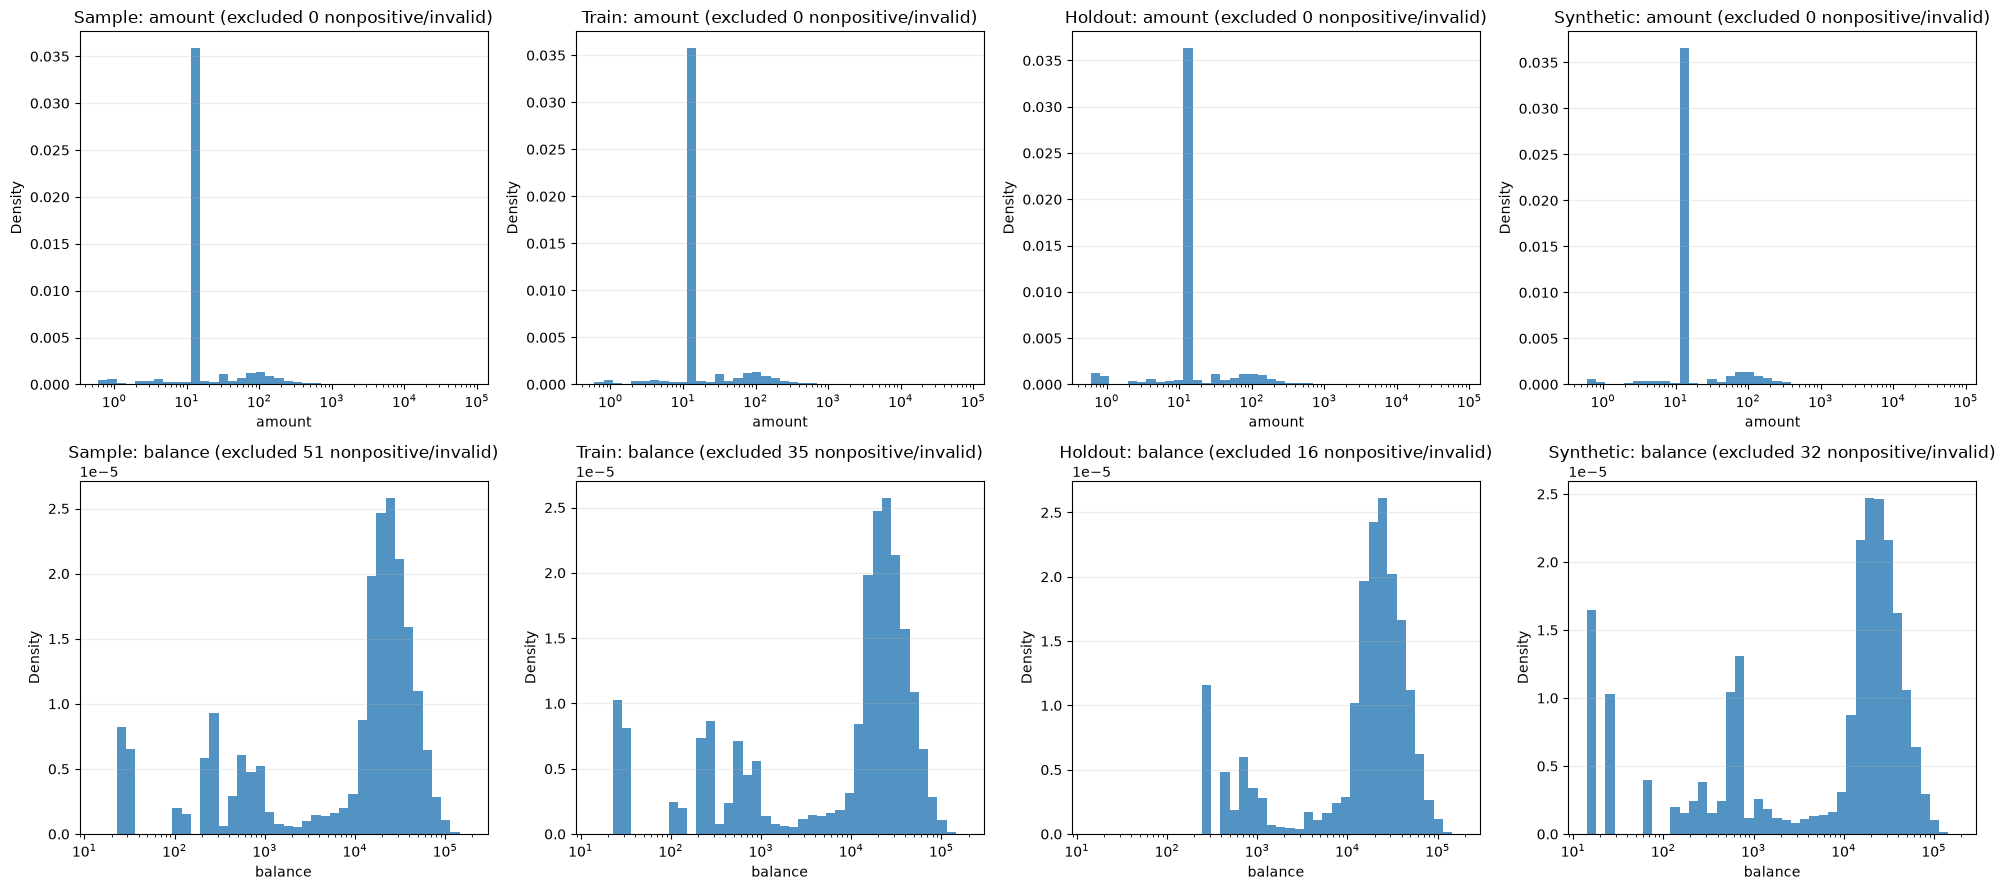

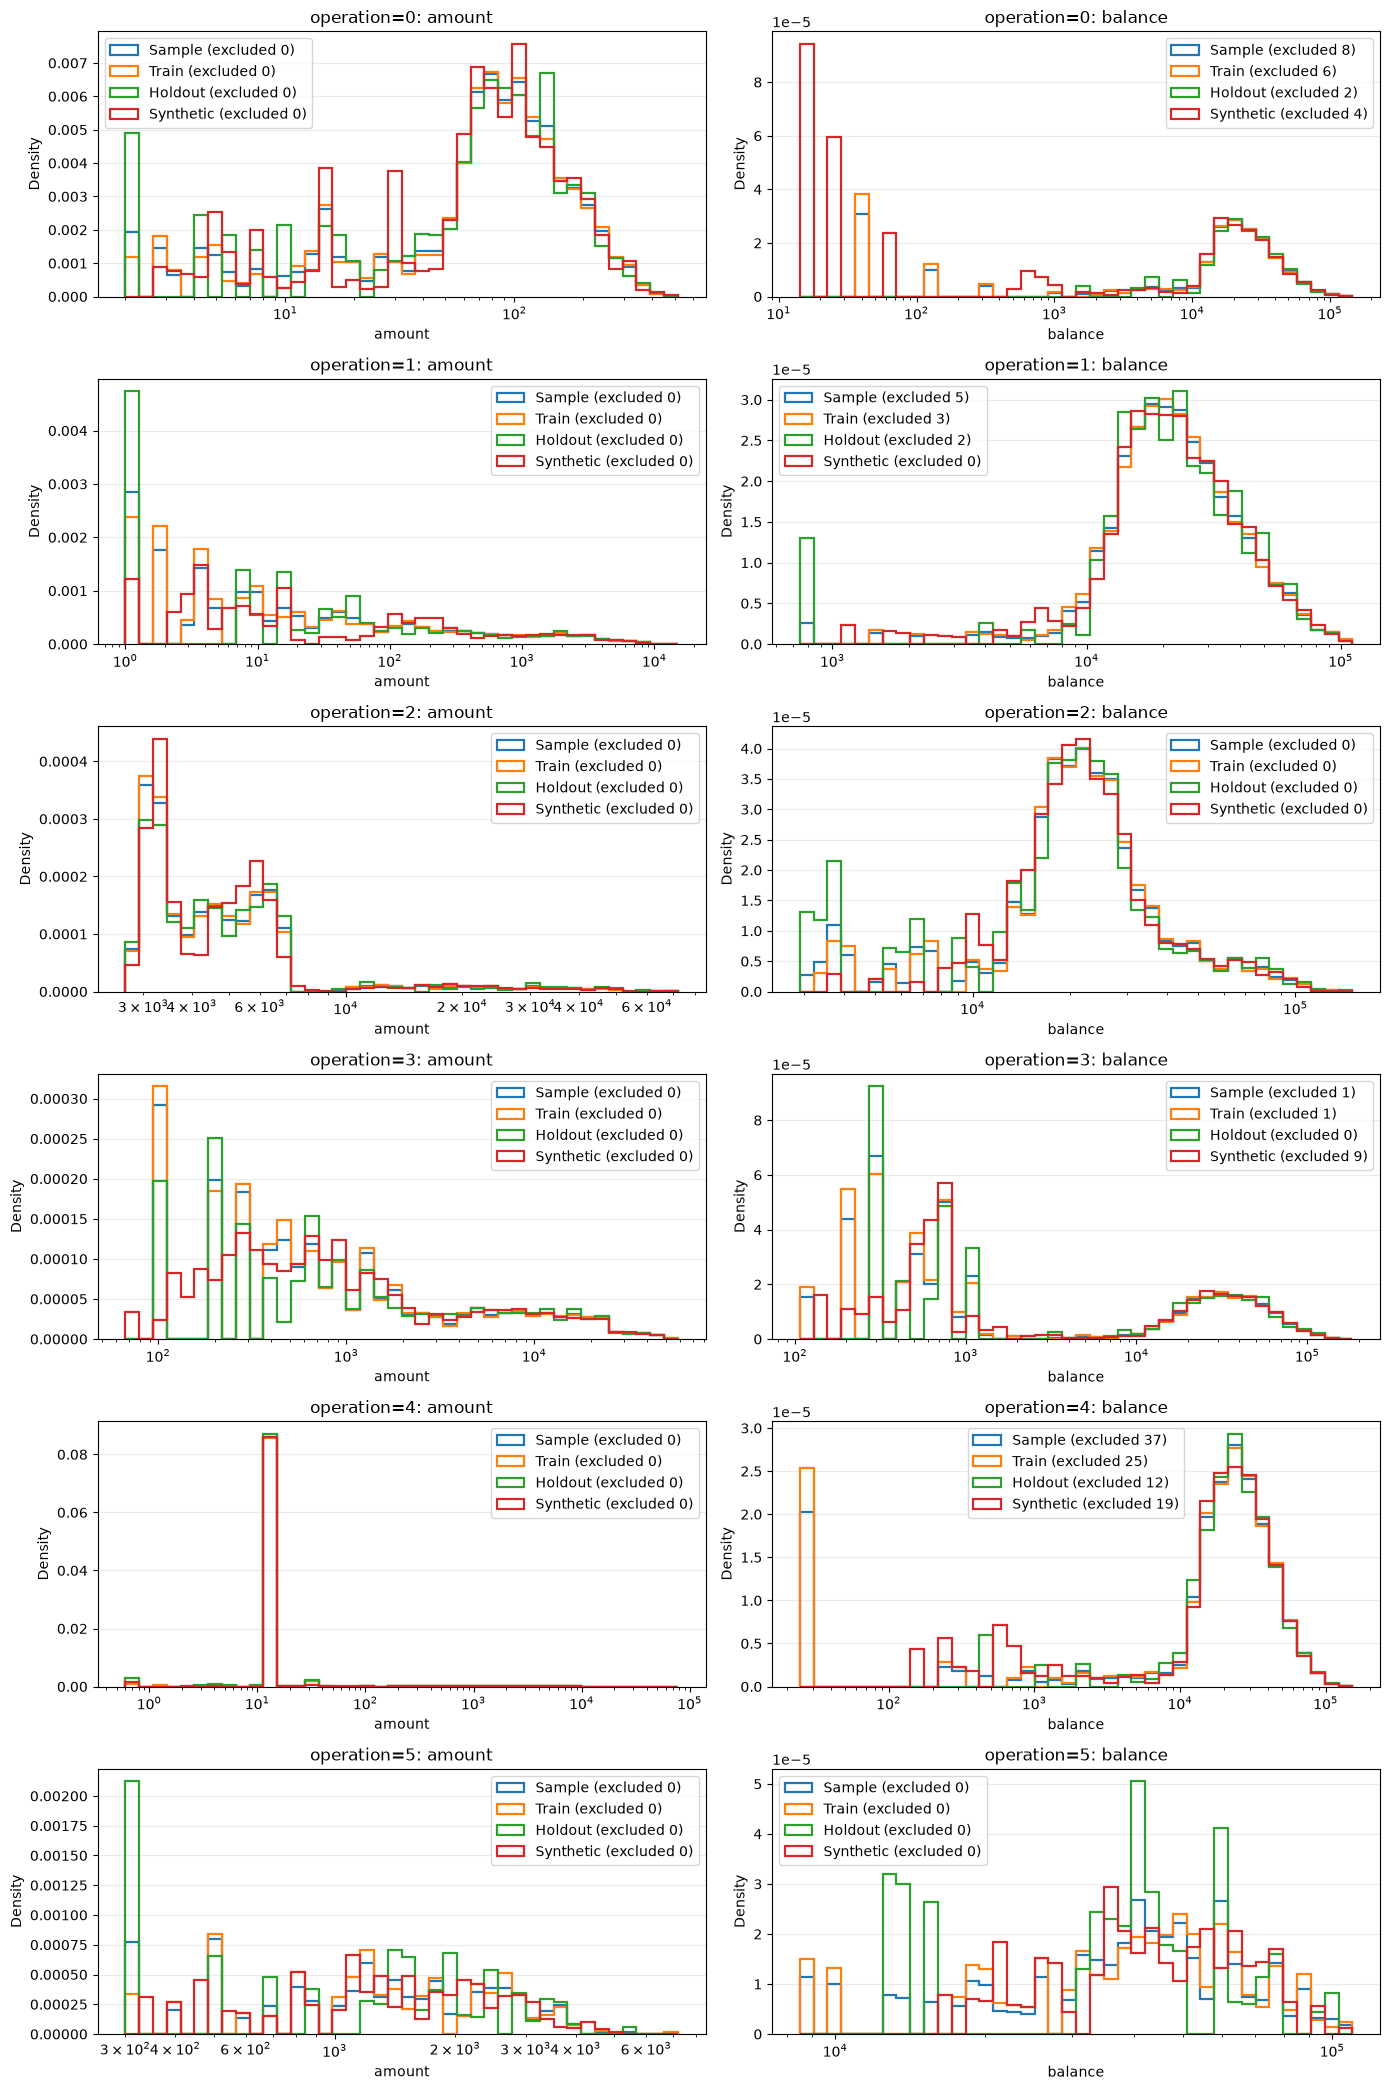

In [3]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

data_dir = Path("implementations/tabular_data/single_table/data")
data_synthetic_dir = Path("implementations/tabular_data/single_table/results/single_table_synthesizing/trans/_final")
train_df = pd.read_csv(data_dir / "trans.csv")
holdout_df = pd.read_csv(data_dir / "trans_holdout.csv")
sample_df = pd.concat([train_df, holdout_df], ignore_index=True)
file_csv = pd.read_csv(data_synthetic_dir / "trans_synthetic.csv")
frames = {
    "Sample": sample_df,
    "Train": train_df,
    "Holdout": holdout_df,
    "Synthetic": file_csv,
}
features = ["amount", "balance"]


def positive_values(frame, column):
    values = pd.to_numeric(frame[column], errors="coerce").to_numpy(dtype=float)
    valid = np.isfinite(values) & (values > 0)
    return values[valid], int((~valid).sum())


def shared_log_bins(frame_groups, column, bins=40):
    positive = [positive_values(frame, column)[0] for frame in frame_groups]
    positive = [values for values in positive if values.size]
    if not positive:
        return None

    values = np.concatenate(positive)
    lower, upper = values.min(), values.max()
    if lower == upper:
        lower, upper = lower / 1.001, upper * 1.001
    return np.geomspace(lower, upper, bins + 1)


# Overall amount and balance distributions across the sample, splits, and synthetic data.
fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex="row")
for row, feature in enumerate(features):
    bins = shared_log_bins(frames.values(), feature)
    for column, (frame_name, frame) in enumerate(frames.items()):
        ax = axes[row, column]
        values, excluded = positive_values(frame, feature)
        if values.size and bins is not None:
            ax.hist(values, bins=bins, density=True, color="#2878B5", alpha=0.8)
        else:
            ax.text(0.5, 0.5, "No positive values", ha="center", va="center", transform=ax.transAxes)
        ax.set_xscale("log")
        ax.set_title(f"{frame_name}: {feature} (excluded {excluded} nonpositive/invalid)")
        ax.set_xlabel(feature)
        ax.set_ylabel("Density")
        ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


# Compare the same distributions separately for each encoded operation value.
operation_values = pd.concat(
    [pd.to_numeric(frame["operation"], errors="coerce") for frame in frames.values()],
    ignore_index=True,
).dropna().unique()
operation_values = sorted(operation_values)
fig, axes = plt.subplots(len(operation_values), 2, figsize=(14, 3.5 * len(operation_values)), squeeze=False)
for row, operation_value in enumerate(operation_values):
    operation_frames = {}
    for frame_name, frame in frames.items():
        operation_codes = pd.to_numeric(frame["operation"], errors="coerce")
        operation_frames[frame_name] = frame.loc[operation_codes == operation_value]

    for column, feature in enumerate(features):
        ax = axes[row, column]
        bins = shared_log_bins(operation_frames.values(), feature)
        for frame_name, frame in operation_frames.items():
            values, excluded = positive_values(frame, feature)
            if values.size and bins is not None:
                ax.hist(
                    values,
                    bins=bins,
                    density=True,
                    histtype="step",
                    linewidth=1.6,
                    label=f"{frame_name} (excluded {excluded})",
                )
        ax.set_xscale("log")
        ax.set_title(f"operation={operation_value}: {feature}")
        ax.set_xlabel(feature)
        ax.set_ylabel("Density")
        ax.grid(axis="y", alpha=0.25)
        ax.legend()
fig.tight_layout()
plt.show()

Statistical Assessment

### 1) Tail Quantile Error

- Formula:

  - `Err_q95 = |q95_syn - q95_real| / q95_real`

  - `Err_q99 = |q99_syn - q99_real| / q99_real`

- Default thresholds:

  - Pass if `Err_q95 <= 0.10`

  - Pass if `Err_q99 <= 0.15`

 

### 2) Tail Mass Ratio

- Formula:

  - `TMR95 = P_syn(amount >= q95_real) / P_real(amount >= q95_real)`

  - `TMR99 = P_syn(amount >= q99_real) / P_real(amount >= q99_real)`

- Default thresholds:

  - Pass if `0.80 <= TMR95 <= 1.20`

  - Pass if `0.70 <= TMR99 <= 1.30`

 

### 3) Tail Distribution Distance (Upper Tail)

- Slice: rows where `amount >= q95_real`

- Formula:

  - `KS95 = KS(real_tail95.amount, syn_tail95.amount)`

  - Optional: `W95 = Wasserstein(real_tail95.amount, syn_tail95.amount)`

- Default thresholds:

  - Pass if `KS95 <= 0.12`

  - Optional pass if `W95 <= 0.20 * std(real_tail95.amount)`

 

### 4) Rare Type Frequency Error

- For each rare type `t in R`:

  - `FreqErr(t) = |p_syn(t) - p_real(t)|`

- Aggregate:

  - `MAE_rare = mean_{t in R}(FreqErr(t))`

- Default thresholds:

  - Pass if `MAE_rare <= 0.01`

  - No individual rare type with `FreqErr(t) > 0.03`

 

### 5) Rare Type Coverage

- Formula:

  - `Coverage_rare = |{t in R : count_syn(t) > 0}| / |R|`

- Default threshold:

  - Pass if `Coverage_rare >= 0.95`

 

### 6) Rare Pair Co-Occurrence Preservation (Optional)

- Build rare pair set `P` from real where pair support in `[min_sup, max_sup]`

- Formula:

  - `PairMAE = mean_{p in P} |p_syn(p) - p_real(p)|`

- Default threshold:

  - Pass if `PairMAE <= 0.005`

 

### 7) Fraud Utility Proxy (Model-to-Model Transfer)

Train the same classifier twice:

- Model A: train on real train, eval on real holdout

- Model B: train on synthetic, eval on real holdout

 

Use PR-AUC (or Recall@K for severe imbalance).

- Formula:

  - `UtilityGap = (Metric_A - Metric_B) / Metric_A`

- Default threshold:

  - Pass if `UtilityGap <= 0.10`

In [4]:
from scipy.stats import ks_2samp

real_amount = pd.to_numeric(holdout_df["amount"], errors="coerce").to_numpy(dtype=float)
synthetic_amount = pd.to_numeric(file_csv["amount"], errors="coerce").to_numpy(dtype=float)
real_amount = real_amount[np.isfinite(real_amount)]
synthetic_amount = synthetic_amount[np.isfinite(synthetic_amount)]

if not real_amount.size or not synthetic_amount.size:
    raise ValueError("Real holdout and synthetic data must both contain finite amount values.")

q95_real, q99_real = np.quantile(real_amount, [0.95, 0.99])
q95_synthetic, q99_synthetic = np.quantile(synthetic_amount, [0.95, 0.99])
err_95 = abs(q95_synthetic - q95_real) / abs(q95_real) if q95_real else np.nan
err_99 = abs(q99_synthetic - q99_real) / abs(q99_real) if q99_real else np.nan


def calculate_tail_metrics(threshold):
    real_tail = real_amount[real_amount >= threshold]
    synthetic_tail = synthetic_amount[synthetic_amount >= threshold]
    p_real = real_tail.size / real_amount.size
    p_synthetic = synthetic_tail.size / synthetic_amount.size
    tmr = p_synthetic / p_real if p_real else np.nan
    ks = ks_2samp(real_tail, synthetic_tail).statistic if real_tail.size and synthetic_tail.size else np.nan
    return p_real, p_synthetic, tmr, ks


p_real_95, p_synthetic_95, tmr_95, ks_95 = calculate_tail_metrics(q95_real)
p_real_99, p_synthetic_99, tmr_99, ks_99 = calculate_tail_metrics(q99_real)


def pass_status(value, passed):
    if not np.isfinite(value):
        return "NOT TESTABLE"
    return "PASS" if passed else "FAIL"


err_95_status = pass_status(err_95, err_95 <= 0.10)
err_99_status = pass_status(err_99, err_99 <= 0.15)
tmr_95_status = pass_status(tmr_95, 0.80 <= tmr_95 <= 1.20)
tmr_99_status = pass_status(tmr_99, 0.70 <= tmr_99 <= 1.30)
ks_95_status = pass_status(ks_95, ks_95 <= 0.12)

results = pd.DataFrame([
    {"Metric": "p_95", "Real": q95_real, "Synthetic": q95_synthetic, "Test result": np.nan, "Threshold": "Reference quantiles", "Status": "N/A"},
    {"Metric": "p_99", "Real": q99_real, "Synthetic": q99_synthetic, "Test result": np.nan, "Threshold": "Reference quantiles", "Status": "N/A"},
    {"Metric": "Err_95", "Real": np.nan, "Synthetic": np.nan, "Test result": err_95, "Threshold": "<= 0.10", "Status": err_95_status},
    {"Metric": "Err_99", "Real": np.nan, "Synthetic": np.nan, "Test result": err_99, "Threshold": "<= 0.15", "Status": err_99_status},
    {"Metric": "TMR95", "Real": p_real_95, "Synthetic": p_synthetic_95, "Test result": tmr_95, "Threshold": "0.80 to 1.20", "Status": tmr_95_status},
    {"Metric": "TMR99", "Real": p_real_99, "Synthetic": p_synthetic_99, "Test result": tmr_99, "Threshold": "0.70 to 1.30", "Status": tmr_99_status},
    {"Metric": "KS95", "Real": np.nan, "Synthetic": np.nan, "Test result": ks_95, "Threshold": "<= 0.12", "Status": ks_95_status}
])

print(f"Real comparison set: holdout_df ({real_amount.size} finite amount values)")
print(f"Synthetic comparison set: file_csv ({synthetic_amount.size} finite amount values)")
print(results.to_string(index=False, float_format=lambda value: f"{value:.6f}"))

threshold_statuses = [err_95_status, err_99_status, tmr_95_status, tmr_99_status, ks_95_status]
if "NOT TESTABLE" in threshold_statuses:
    overall_status = "NOT TESTABLE"
else:
    overall_status = "PASS" if all(value == "PASS" for value in threshold_statuses) else "FAIL"
print(f"Overall status for metrics with defined thresholds: {overall_status}")

Real comparison set: holdout_df (4000 finite amount values)
Synthetic comparison set: file_csv (16000 finite amount values)
Metric         Real    Synthetic  Test result           Threshold Status
  p_95 26019.750000 24858.609246          NaN Reference quantiles    N/A
  p_99 46901.000000 45129.062153          NaN Reference quantiles    N/A
Err_95          NaN          NaN     0.044625             <= 0.10   PASS
Err_99          NaN          NaN     0.037780             <= 0.15   PASS
 TMR95     0.050000     0.047000     0.940000        0.80 to 1.20   PASS
 TMR99     0.010000     0.007687     0.768750        0.70 to 1.30   PASS
  KS95          NaN          NaN     0.052181             <= 0.12   PASS
Overall status for metrics with defined thresholds: PASS


In [5]:
import json
from logging import INFO

import pandas as pd
from midst_toolkit.common.logger import log
from midst_toolkit.evaluation.privacy import (
    DistanceToClosestRecordScore,
    EpsilonIdentifiabilityRisk,
    HittingRate,
    MedianDistanceToClosestRecordScore,
    NearestNeighborDistanceRatio,
)
from midst_toolkit.evaluation.privacy.distance_preprocess import preprocess_for_distance_computation
from midst_toolkit.evaluation.privacy.distance_utils import NormType
from midst_toolkit.evaluation.privacy.epsilon_identifiability_risk import EpsilonIdentifiabilityNorm
from midst_toolkit.evaluation.privacy.distance_closest_record import MedianDistanceToClosestRecordScore
from implementations.tabular_data.evaluation.display_utils import log_metrics

# Local imports
from implementations.tabular_data.evaluation.preprocessing import (
    get_numerical_and_categorical_column_names,
    syntheval_preprocess,
)


# Turn off chained-assignment warnings for the whole notebook
pd.options.mode.chained_assignment = None

/home/coder/synthetic-data-bootcamp/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
from implementations.tabular_data.haoli_implementation.utils import generate_synthetic_data
import pandas as pd
for seed in range(1,10):
    synthetic_data = generate_synthetic_data(seed=seed)
    synthetic_data.to_csv(f"implementations/tabular_data/single_table/results/single_table_synthesizing/trans/_final/synthetic_data_seed_{seed}.csv", index=False)

INFO :      Setting random seeds to 1.
INFO :      Checking for a pre-trained model in /home/coder/synthetic-data-bootcamp/implementations/tabular_data/single_table/results...
INFO :      Training data ratio is 1, so the data will not be split into training and test sets.
INFO :      Train dataframe shape: (16000, 8)
INFO :      Total dataframe shape: (16000, 8)
INFO :      Numerical data shape: (16000, 4)
INFO :      Categorical data shape: (16000, 4)


INFO :      Synthesizing data...
INFO :      Generating None -> trans
INFO :      Sample size: 16000
INFO :      Data synthesized successfully.
INFO :      Setting random seeds to 2.
INFO :      Checking for a pre-trained model in /home/coder/synthetic-data-bootcamp/implementations/tabular_data/single_table/results...
INFO :      Training data ratio is 1, so the data will not be split into training and test sets.
INFO :      Train dataframe shape: (16000, 8)
INFO :      Total dataframe shape: (16000, 8)
INFO :      Numerical data shape: (16000, 4)
INFO :      Categorical data shape: (16000, 4)
INFO :      Synthesizing data...
INFO :      Generating None -> trans
INFO :      Sample size: 16000
INFO :      Data synthesized successfully.
INFO :      Setting random seeds to 3.
INFO :      Checking for a pre-trained model in /home/coder/synthetic-data-bootcamp/implementations/tabular_data/single_table/results...
INFO :      Training data ratio is 1, so the data will not be split into traini

In [14]:
ROOT = Path.cwd()
IMPLEMENTATION_ROOT = ROOT / "implementations" / "tabular_data" / "single_table"
# Set data and output directories
base_data_dir = IMPLEMENTATION_ROOT / "data"
base_output_dir = IMPLEMENTATION_ROOT / "results"

TABLE_NAME = "trans"
with open(base_data_dir / "meta_info.json", "r") as f:
    meta_info = json.load(f)

hitting_rate_results = pd.DataFrame(columns=["Seed", "Hitting Rate"])
EpsilonIdentifiability_results = pd.DataFrame(columns=["Seed", "Epsilon Identifiability Rate"])
MedianDCR_results = pd.DataFrame(columns=["Seed", "Median DCR"])

real_train_data = pd.read_csv(base_data_dir / f"{TABLE_NAME}.csv")
real_holdout_data = pd.read_csv(base_data_dir / f"{TABLE_NAME}_holdout.csv")
log(INFO, f"Loaded {len(real_train_data)} rows of real training data")
log(INFO, f"Loaded {len(real_holdout_data)} rows of real holdout data")
for seed in range(1, 10):
    synthetic_data = pd.read_csv(base_output_dir / "single_table_synthesizing/trans/_final" / f"synthetic_data_seed_{seed}.csv")
    log(INFO, f"Loaded {len(synthetic_data)} rows of synthetic data")
    log(INFO, "Preprocessing Data with SynthEval pipeline")
    numerical_columns, categorical_columns = get_numerical_and_categorical_column_names(real_train_data, meta_info)
# Categorical values are ordinal encoded, numerical values are min-max scaled
    syntheval_real_data_train, syntheval_synthetic_data, syntheval_real_data_holdout = syntheval_preprocess(
        numerical_columns,
        categorical_columns,
        real_train_data,
        synthetic_data,
        real_holdout_data,
    )
    log(INFO, "Running Hitting Rate Evaluation")
    # Hyper-parameter
    hitting_threshold = 0.03

    metric = HittingRate(
        categorical_columns=categorical_columns,
        numerical_columns=numerical_columns,
        hitting_threshold=hitting_threshold,
        # Already preprocessing above
        do_preprocess=False,
    )
    results = metric.compute(syntheval_real_data_train, syntheval_synthetic_data)
    log_metrics(f"Hitting Rate with Seed = {seed}", results)
    hitting_rate_results = pd.concat([hitting_rate_results, pd.DataFrame([{"Seed": seed, "Hitting Rate": results['hitting_rate']}])], ignore_index=True)

    log(INFO, "Running Epsilon Identifiability Rate Evaluation")
    # Categorical values are ordinal encoded, numerical values are min-max scaled
    metric = EpsilonIdentifiabilityRisk(
        categorical_columns=categorical_columns,
        numerical_columns=numerical_columns,
        norm=EpsilonIdentifiabilityNorm("gower"),  # Options are "euclid" and "gower".
        # Already preprocessing above
        do_preprocess=False,
    )
    results = metric.compute(syntheval_real_data_train, syntheval_synthetic_data)
    log_metrics(f"Epsilon Identifiability Rate with Seed = {seed}", results)
    EpsilonIdentifiability_results = pd.concat([EpsilonIdentifiability_results, pd.DataFrame([{"Seed": seed, "Epsilon Identifiability Rate": results['epsilon_identifiability_risk']}])], ignore_index=True)
    
    log(INFO, "Running Median DCR Evaluation")
    # Hyper-parameters
    norm = "l2"
    batch_size = 1000
    metric = MedianDistanceToClosestRecordScore(
        NormType(norm),
        batch_size,
        do_preprocess=False,
    )
    ROOT = Path.cwd()
    IMPLEMENTATION_ROOT = ROOT / "implementations" / "tabular_data" / "single_table"
    # Set data and output directories
    base_data_dir = IMPLEMENTATION_ROOT / "data"
    with open(base_data_dir / "meta_info.json", "r") as f:
        meta_info = json.load(f)
    distance_real_data, distance_synthetic_data, distance_holdout_data = preprocess_for_distance_computation(
        meta_info=meta_info,
        real_data_train=real_train_data,
        synthetic_data=synthetic_data,
        real_data_test=real_holdout_data,
    )
    results = metric.compute(distance_real_data, distance_synthetic_data)
    log_metrics(f"Median Distance To Closest Record Score with Seed = {seed}", results)
    MedianDCR_results = pd.concat([MedianDCR_results, pd.DataFrame([{"Seed": seed, "Median DCR": results['median_dcr_score']}])], ignore_index=True)

INFO :      Loaded 16000 rows of real training data
INFO :      Loaded 4000 rows of real holdout data
INFO :      Loaded 16000 rows of synthetic data
INFO :      Preprocessing Data with SynthEval pipeline
INFO :      Running Hitting Rate Evaluation


INFO :      
Hitting Rate with Seed = 1
--------------------------------------------------------------------------------

INFO :      Metric: hitting_rate	Score: 0.7010625
INFO :      --------------------------------------------------------------------------------

/tmp/ipykernel_987089/2292056529.py:45: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  hitting_rate_results = pd.concat([hitting_rate_results, pd.DataFrame([{"Seed": seed, "Hitting Rate": results['hitting_rate']}])], ignore_index=True)
INFO :      Running Epsilon Identifiability Rate Evaluation
Computing nearest neighbor distances from real/holdout dataset to synthetic dataset.: 100%|██████████| 125/125 [00:11<00:00, 10.74it/s]
INFO :      
Epsilon Identifiability Rate with Seed =

In [15]:
hitting_rate_results

,Seed,Hitting Rate
0,1,0.701063
1,2,0.699625
2,3,0.700750
3,4,0.699688
4,5,0.701812
5,6,0.699750
6,7,0.699063
7,8,0.700313
8,9,0.697500


In [16]:
EpsilonIdentifiability_results

,Seed,Epsilon Identifiability Rate
0,1,0.440250
1,2,0.438312
2,3,0.439500
3,4,0.440188
4,5,0.442250
5,6,0.433125
6,7,0.434688
7,8,0.443250
8,9,0.437500


In [18]:
MedianDCR_results

,Seed,Median DCR
0,1,1.000641
1,2,1.010179
2,3,1.016028
3,4,1.006043
4,5,1.038804
5,6,1.021203
6,7,1.003407
7,8,1.004424
8,9,1.011296
